<a href="https://colab.research.google.com/github/DiegoMauricioSuaza/ActividadUno/blob/main/S25_M%C3%B3dulo_2_Actividad_did%C3%A1ctica_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== REPORTE DE ANALÍTICA E-COMMERCE ===
Secuencia de observaciones (Últimas 10): ['Click', 'Scroll', 'Click', 'Scroll', 'Scroll', 'Scroll', 'Click', 'Click', 'Compra', 'Scroll']
Intención real vs Predicha (Viterbi) coinciden en: 45.0%

--- Métricas Clave ---
Conversión lograda: ✅ Sí
Puntos de abandono (Fricción): 6
Tiempo promedio (acciones) por fase:
  - Navegando: 9 acciones
  - Buscando: 18 acciones
  - Comprando: 13 acciones

--- Recomendaciones de UX ---
🔴 Alto abandono detectado: Los usuarios retroceden mucho a 'Navegando'.
   -> UX Fix: Mejorar la persistencia del carrito y simplificar los filtros de búsqueda.
🟡 Fricción en la búsqueda: El usuario pasa demasiado tiempo buscando.
   -> UX Fix: Implementar un motor de búsqueda predictivo o destacar productos recomendados.
🟢 Sesión exitosa.
   -> UX Fix: Optimizar flujo de checkout a 1-click para reducir fricción futura.


/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 128065 (\N{EYE}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 128722 (\N{SHOPPING TROLLEY}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128065 (\N{EYE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128269 (\N{LEFT-POINTING MAGNIFYING GLASS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128722 (\N{SHOPPING T

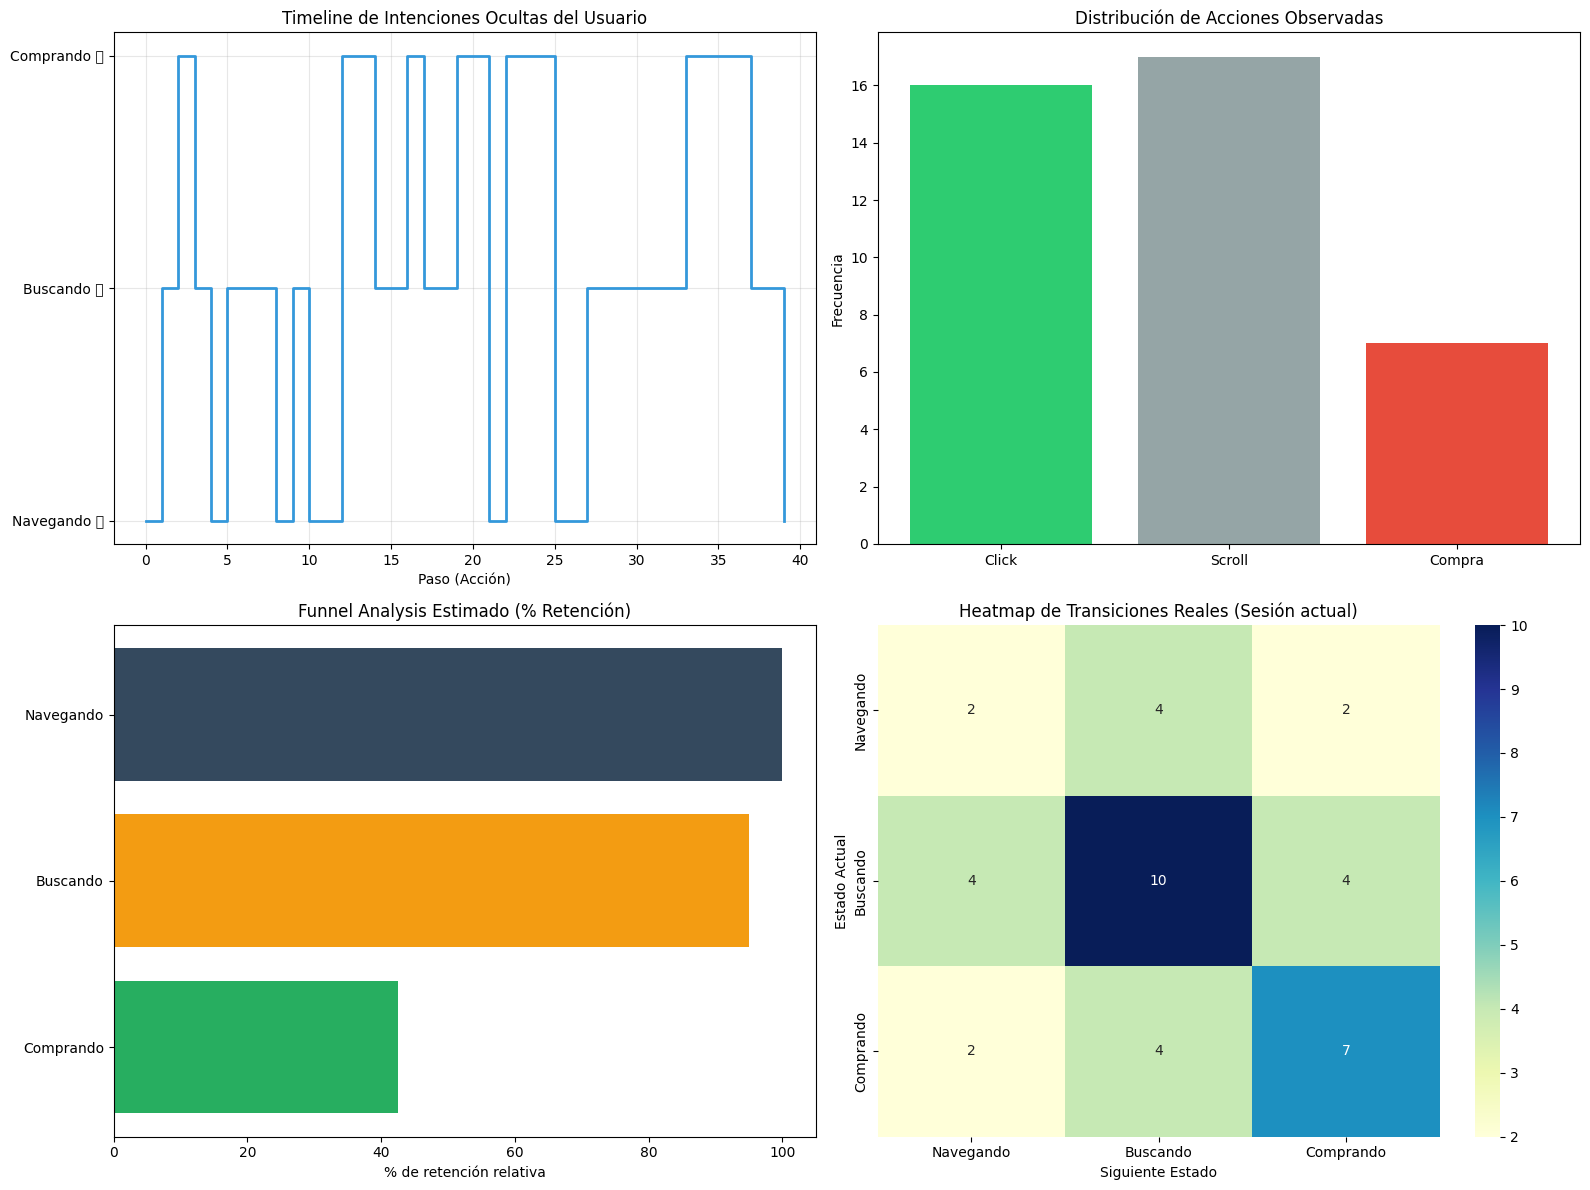

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

class HMMWebAnalytics:
    def __init__(self):
        # Definición de estados y observaciones
        self.states = ['Navegando', 'Buscando', 'Comprando']
        self.observations = ['Click', 'Scroll', 'Compra']

        # Mapeo para índices
        self.state_idx = {s: i for i, s in enumerate(self.states)}
        self.obs_idx = {o: i for i, s, o in zip(range(3), self.states, self.observations)}

        # Distribución Inicial
        self.pi = np.array([0.6, 0.3, 0.1])

        # Matriz de Transición (A)
        self.A = np.array([
            [0.5, 0.4, 0.1],  # Desde Navegando
            [0.3, 0.5, 0.2],  # Desde Buscando
            [0.2, 0.3, 0.5]   # Desde Comprando
        ])

        # Matriz de Emisión (B)
        self.B = np.array([
            [0.6, 0.35, 0.05], # Desde Navegando
            [0.5, 0.4,  0.1],  # Desde Buscando
            [0.2, 0.3,  0.5]   # Desde Comprando
        ])

    def simulate_session(self, n_steps=40):
        """Simula una sesión de usuario de n acciones."""
        states_seq = []
        obs_seq = []

        # Estado inicial
        current_state = np.random.choice(3, p=self.pi)

        for _ in range(n_steps):
            states_seq.append(self.states[current_state])

            # Generar observación basada en el estado actual
            current_obs = np.random.choice(3, p=self.B[current_state])
            obs_seq.append(self.observations[current_obs])

            # Transición al siguiente estado
            current_state = np.random.choice(3, p=self.A[current_state])

        return states_seq, obs_seq

    def viterbi_predict(self, obs_seq):
        """Implementa el algoritmo de Viterbi para predecir la secuencia de estados ocultos."""
        T = len(obs_seq)
        N = len(self.states)

        V = np.zeros((N, T))
        ptr = np.zeros((N, T), dtype=int)

        # Inicialización
        obs_idx_seq = [self.observations.index(o) for o in obs_seq]
        V[:, 0] = self.pi * self.B[:, obs_idx_seq[0]]

        # Recursión
        for t in range(1, T):
            for s in range(N):
                seq_probs = V[:, t-1] * self.A[:, s] * self.B[s, obs_idx_seq[t]]
                V[s, t] = np.max(seq_probs)
                ptr[s, t] = np.argmax(seq_probs)

        # Terminación y Backtracking
        best_path = np.zeros(T, dtype=int)
        best_path[-1] = np.argmax(V[:, -1])

        for t in range(T-2, -1, -1):
            best_path[t] = ptr[best_path[t+1], t+1]

        return [self.states[i] for i in best_path]

    def calculate_metrics(self, states_seq, obs_seq):
        """Calcula métricas clave de e-commerce basadas en la sesión."""
        metrics = {}

        # 1. Tasa de conversión (Llegó a Comprando)
        metrics['conversion'] = 'Comprando' in states_seq

        # 2. Tiempo promedio en cada fase (acciones por estado)
        state_counts = Counter(states_seq)
        metrics['avg_time'] = {s: state_counts.get(s, 0) for s in self.states}

        # 3. Puntos de abandono (Transiciones de Buscando/Comprando hacia Navegando)
        drop_offs = 0
        for i in range(len(states_seq)-1):
            if states_seq[i] in ['Buscando', 'Comprando'] and states_seq[i+1] == 'Navegando':
                drop_offs += 1
        metrics['drop_offs'] = drop_offs

        return metrics

    def generate_ux_recommendations(self, states_seq, metrics):
        """Genera recomendaciones de UX basadas en los patrones de la sesión."""
        recs = ["\n--- Recomendaciones de UX ---"]

        if metrics['drop_offs'] > 3:
            recs.append("🔴 Alto abandono detectado: Los usuarios retroceden mucho a 'Navegando'.")
            recs.append("   -> UX Fix: Mejorar la persistencia del carrito y simplificar los filtros de búsqueda.")

        if metrics['avg_time']['Buscando'] > 15:
            recs.append("🟡 Fricción en la búsqueda: El usuario pasa demasiado tiempo buscando.")
            recs.append("   -> UX Fix: Implementar un motor de búsqueda predictivo o destacar productos recomendados.")

        if not metrics['conversion']:
            recs.append("⚪ Sesión sin conversión.")
            recs.append("   -> UX Fix: Ofrecer un pop-up de descuento por intención de salida (Exit-Intent).")
        else:
            recs.append("🟢 Sesión exitosa.")
            recs.append("   -> UX Fix: Optimizar flujo de checkout a 1-click para reducir fricción futura.")

        return "\n".join(recs)

    def visualize_dashboard(self, states_seq, obs_seq):
        """Genera un panel de visualización completo."""
        fig = plt.figure(figsize=(16, 12))

        # 1. Timeline de Intenciones (con íconos)
        ax1 = plt.subplot(2, 2, 1)
        y_vals = [self.state_idx[s] for s in states_seq]
        x_vals = range(len(states_seq))

        ax1.step(x_vals, y_vals, where='post', color='#3498db', linewidth=2)
        ax1.set_yticks([0, 1, 2])
        # Usamos texto + emoji por compatibilidad de fuentes en matplotlib
        ax1.set_yticklabels(['Navegando 👁️', 'Buscando 🔍', 'Comprando 🛒'])
        ax1.set_title('Timeline de Intenciones Ocultas del Usuario')
        ax1.set_xlabel('Paso (Acción)')
        ax1.grid(True, alpha=0.3)

        # 2. Gráfico de Acciones Observadas
        ax2 = plt.subplot(2, 2, 2)
        obs_counts = Counter(obs_seq)
        colors = ['#e74c3c' if o=='Compra' else '#95a5a6' if o=='Scroll' else '#2ecc71' for o in self.observations]
        ax2.bar(self.observations, [obs_counts.get(o, 0) for o in self.observations], color=colors)
        ax2.set_title('Distribución de Acciones Observadas')
        ax2.set_ylabel('Frecuencia')

        # 3. Funnel de Conversión Visual
        ax3 = plt.subplot(2, 2, 3)
        unique_users_in_phase = [
            100, # 100% empieza navegando/existiendo en la web
            (state_counts := Counter(states_seq)).get('Buscando', 0) / len(states_seq) * 100 + 20, # Simplificación visual
            state_counts.get('Comprando', 0) / len(states_seq) * 100
        ]
        # Ajuste de embudo estricto descendente para visualización
        funnel_data = [100, min(100, unique_users_in_phase[1]+30), min(unique_users_in_phase[1]+30, unique_users_in_phase[2]+10)]

        y_pos = np.arange(len(self.states))
        ax3.barh(y_pos, funnel_data, color=['#34495e', '#f39c12', '#27ae60'], align='center')
        ax3.set_yticks(y_pos)
        ax3.set_yticklabels(self.states)
        ax3.invert_yaxis()  # Embudo de arriba hacia abajo
        ax3.set_title('Funnel Analysis Estimado (% Retención)')
        ax3.set_xlabel('% de retención relativa')

        # 4. Heatmap de Transiciones (Empírico de la sesión)
        ax4 = plt.subplot(2, 2, 4)
        trans_matrix = np.zeros((3, 3))
        for i in range(len(states_seq)-1):
            curr_s = self.state_idx[states_seq[i]]
            next_s = self.state_idx[states_seq[i+1]]
            trans_matrix[curr_s, next_s] += 1

        sns.heatmap(trans_matrix, annot=True, cmap='YlGnBu',
                    xticklabels=self.states, yticklabels=self.states, ax=ax4)
        ax4.set_title('Heatmap de Transiciones Reales (Sesión actual)')
        ax4.set_ylabel('Estado Actual')
        ax4.set_xlabel('Siguiente Estado')

        plt.tight_layout()
        plt.show()

# --- Ejecución del Análisis ---
if __name__ == "__main__":
    # Inicializar modelo
    hmm = HMMWebAnalytics()

    # 1. Simular 40 acciones
    acciones = 40
    hidden_states, observations = hmm.simulate_session(n_steps=acciones)

    # 2. Predecir intención (Viterbi) y analizar patrones
    predicted_states = hmm.viterbi_predict(observations)

    # 3. Calcular Métricas
    metrics = hmm.calculate_metrics(hidden_states, observations)

    print("=== REPORTE DE ANALÍTICA E-COMMERCE ===")
    print(f"Secuencia de observaciones (Últimas 10): {observations[-10:]}")
    print(f"Intención real vs Predicha (Viterbi) coinciden en: "
          f"{sum(1 for r, p in zip(hidden_states, predicted_states) if r == p)/acciones * 100:.1f}%")

    print("\n--- Métricas Clave ---")
    print(f"Conversión lograda: {'✅ Sí' if metrics['conversion'] else '❌ No'}")
    print(f"Puntos de abandono (Fricción): {metrics['drop_offs']}")
    print("Tiempo promedio (acciones) por fase:")
    for estado, tiempo in metrics['avg_time'].items():
        print(f"  - {estado}: {tiempo} acciones")

    # 4. Generar Recomendaciones UX
    print(hmm.generate_ux_recommendations(hidden_states, metrics))

    # 5. Visualizar Dashboard
    hmm.visualize_dashboard(hidden_states, observations)